## 1번 셀: 불러오기와 단어 벡터 추출

In [16]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.utils import *
from src.prompts import *
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

tok, enc = load_text_encoder()
d_layers = np.load("../data/gender_dir_layers.npy")

held_words = [w for p in HELDOUT_PAIRS for w in p]
dir_words  = [w for p in DIRECTION_PAIRS for w in p]
eval_words = ALL_JOBS + held_words          # 평가 대상
E_eval = encode_words(eval_words, TEMPLATES, tok, enc)["layers"]   # (n, 13, 768)
E_dir  = encode_words(dir_words,  TEMPLATES, tok, enc)["layers"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## 2번 셀: 2D 지도 함수

In [10]:
from adjustText import adjust_text

nj = len(ALL_JOBS)
group_color = {"male_expected": "tab:blue", "female_expected": "tab:red",
               "neutral_expected": "tab:green"}
job_colors = [group_color[g] for g, js in JOBS.items() for _ in js]
show = [i for i, w in enumerate(ALL_JOBS) if w in DISPLAY_JOBS]     # 표시할 직업 인덱스

def gender_map(L, d):
    """중심과 가로축은 직업 20개 + 검증용 쌍 전체로 정한다 (표시 여부와 무관)."""
    mu = E_eval[:, L].mean(axis=0)
    A = E_eval[:, L] - mu
    y = A @ d
    R = A - np.outer(y, d)
    pca = PCA(n_components=1).fit(R[:nj])
    x = pca.transform(R)[:, 0]
    return x[:nj], y[:nj], y[nj:]               # 직업 x, 직업 y, 검증용 쌍 y

def draw(ax, L, d, title):
    x, y, yh = gender_map(L, d)
    ref_m, ref_f = yh[0::2].mean(), yh[1::2].mean()   # 짝수 = 남, 홀수 = 여

    for i in show:
        ax.annotate("", (x[i], y[i]), (0, 0),
                    arrowprops=dict(arrowstyle="->", color=job_colors[i], alpha=0.6))
    ax.scatter(x[show], y[show], c=[job_colors[i] for i in show], s=12)

    ax.axhline(ref_m, ls="--", c="tab:blue", lw=0.8, alpha=0.5)
    ax.axhline(ref_f, ls="--", c="tab:red", lw=0.8, alpha=0.5)
    ax.axhline(0, c="gray", lw=0.5); ax.axvline(0, c="gray", lw=0.5)

    pad = 0.15
    xs = np.r_[x[show], 0]; ys = np.r_[y[show], 0, ref_m, ref_f]
    ax.set_xlim(xs.min() - pad*np.ptp(xs), xs.max() + pad*np.ptp(xs))
    ax.set_ylim(ys.min() - pad*np.ptp(ys), ys.max() + pad*np.ptp(ys))

    tr = ax.get_yaxis_transform()                # x는 축 비율, y는 데이터 값
    ax.text(0.99, ref_m, "held-out male avg", transform=tr, fontsize=7, ha="right", va="bottom")
    ax.text(0.99, ref_f, "held-out female avg", transform=tr, fontsize=7, ha="right", va="top")

    texts = [ax.text(x[i], y[i], ALL_JOBS[i], fontsize=9, color=job_colors[i]) for i in show]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.4))

    ax.set_title(title); ax.set_xlabel("PC1 of residual (jobs only)")
    ax.set_ylabel("gender projection (up = male)")
    return y                                     # std 비교용 (직업 20개 전체)

## 3번 셀: 성별 방향과 무작위 방향 나란히

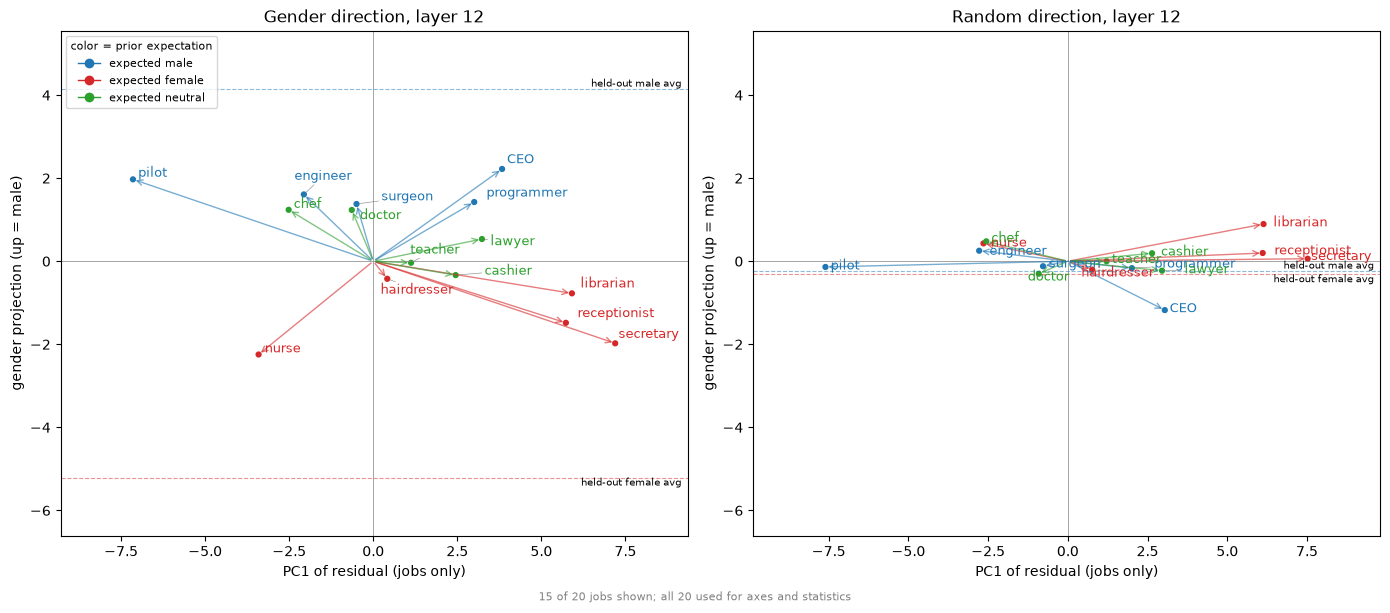

std of job projections (all 20)  gender: 1.45  random: 0.43


In [12]:
L = 12
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
yg = draw(axes[0], L, d_layers[L], f"Gender direction, layer {L}")
yr = draw(axes[1], L, random_direction(seed=RANDOM_DIR_SEED), f"Random direction, layer {L}")
axes[1].set_ylim(axes[0].get_ylim())             # 세로 눈금을 같게 해야 비교가 공정
fig.text(0.5, -0.01, f"{len(show)} of {nj} jobs shown; all {nj} used for axes and statistics",
         ha="center", fontsize=8, color="gray")

from matplotlib.lines import Line2D
handles = [Line2D([], [], color=c, marker="o", lw=1, label=l) for l, c in
           [("expected male", "tab:blue"), ("expected female", "tab:red"),
            ("expected neutral", "tab:green")]]
axes[0].legend(handles=handles, loc="upper left", fontsize=8, title="color = prior expectation",
               title_fontsize=8)

plt.tight_layout(); plt.show()

print("std of job projections (all 20)  gender:", yg.std().round(2), " random:", yr.std().round(2))

## 4번 셀: 층 슬라이더

In [15]:
import plotly.graph_objects as go

LAYERS = range(13)
COLORS = {"male_expected": "#1f77b4", "female_expected": "#d62728", "neutral_expected": "#2ca02c"}
LABELS = {"male_expected": "expected male", "female_expected": "expected female",
          "neutral_expected": "expected neutral"}
scale = np.linalg.norm(E_eval, axis=-1).mean(axis=0)        # 층별 평균 벡터 크기 (13,)

# 12층을 기준으로 고정하고, 아래 층으로 내려가며 부호를 맞춘다
coords, next_x = {}, None
for L in reversed(LAYERS):
    x, y, yh = gender_map(L, d_layers[L])
    if next_x is not None and x @ next_x < 0:
        x = -x
    next_x = x
    s = scale[L]
    coords[L] = (x / s, y / s, yh[0::2].mean() / s, yh[1::2].mean() / s)

# 모든 층에서 같은 축 범위 (그래야 층끼리 비교가 공정)
allx = np.concatenate([c[0][show] for c in coords.values()])
ally = np.concatenate([np.r_[c[1][show], c[2], c[3]] for c in coords.values()])
xr = [allx.min() * 1.15, allx.max() * 1.15]
yr = [ally.min() * 1.15, ally.max() * 1.15]

def make_traces(L):
    x, y, rm, rf = coords[L]
    out = []
    for g in JOBS:
        idx = [i for i in show if ALL_JOBS[i] in JOBS[g]]
        out.append(go.Scatter(                                 # 원점에서 직업까지 선
            x=sum([[0, x[i], None] for i in idx], []), y=sum([[0, y[i], None] for i in idx], []),
            mode="lines", line=dict(color=COLORS[g], width=1), opacity=0.5,
            showlegend=False, hoverinfo="skip"))
        out.append(go.Scatter(                                 # 직업 점과 이름
            x=x[idx], y=y[idx], mode="markers+text", text=[ALL_JOBS[i] for i in idx],
            textposition="top center", marker=dict(color=COLORS[g], size=7), name=LABELS[g]))
    out.append(go.Scatter(x=xr, y=[rm, rm], mode="lines", name="held-out male avg",
                          line=dict(color=COLORS["male_expected"], dash="dash", width=1)))
    out.append(go.Scatter(x=xr, y=[rf, rf], mode="lines", name="held-out female avg",
                          line=dict(color=COLORS["female_expected"], dash="dash", width=1)))
    return out

fig = go.Figure(data=make_traces(12),
                frames=[go.Frame(data=make_traces(L), name=str(L)) for L in LAYERS])
fig.update_layout(
    title="Gender projection of jobs across text-encoder layers",
    xaxis=dict(range=xr, title="PC1 of residual (scaled)", zeroline=True),
    yaxis=dict(range=yr, title="gender projection / layer norm (up = male)", zeroline=True),
    width=900, height=650,
    sliders=[dict(active=12, currentvalue=dict(prefix="Layer "),
                  steps=[dict(label=str(L), method="animate",
                              args=[[str(L)], dict(mode="immediate", frame=dict(duration=0))])
                         for L in LAYERS])])
fig.show()
fig.write_html("../figures/layer_slider.html")             # 발표 시연용

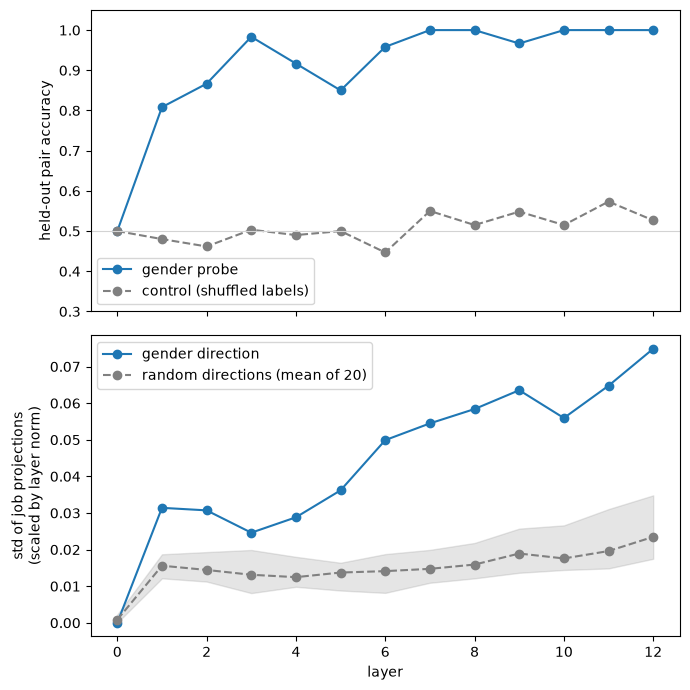

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --- probe 데이터: 20쌍 × 남녀 × 템플릿 3개 = 120 프롬프트 ---
probe_pairs = DIRECTION_PAIRS + HELDOUT_PAIRS + PROBE_PAIRS
prompts, labels, groups = [], [], []
for g, (m, f) in enumerate(probe_pairs):
    for w, lab in [(m, 1), (f, 0)]:
        for t in TEMPLATES:
            prompts.append(fill(t, w)); labels.append(lab); groups.append(g)
H = encode(prompts, tok, enc)["layers"]                     # (120, 13, 768)
labels, groups = np.array(labels), np.array(groups)

cv = GroupKFold(n_splits=5)                                 # 같은 쌍은 같은 fold
def probe_acc(X, y):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    return cross_val_score(clf, X, y, groups=groups, cv=cv).mean()

rng = np.random.default_rng(0)
acc, acc_ctrl = [], []
for L in LAYERS:
    acc.append(probe_acc(H[:, L], labels))
    ctrl = []                                               # 대조군: 쌍마다 라벨을 무작위로 뒤집음
    for _ in range(5):
        flip = rng.integers(0, 2, size=len(probe_pairs))
        ctrl.append(probe_acc(H[:, L], labels ^ flip[groups]))
    acc_ctrl.append(np.mean(ctrl))

# --- 직업 투영값 std: 성별 방향 vs 무작위 방향 20개 ---
std_gender = [gender_map(L, d_layers[L])[1].std() / scale[L] for L in LAYERS]
std_rand = np.array([[gender_map(L, random_direction(seed=s))[1].std() / scale[L]
                      for s in range(20)] for L in LAYERS])  # (13, 20)

fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
axes[0].plot(LAYERS, acc, "o-", label="gender probe")
axes[0].plot(LAYERS, acc_ctrl, "o--", c="gray", label="control (shuffled labels)")
axes[0].axhline(0.5, c="lightgray", lw=0.8)
axes[0].set_ylabel("held-out pair accuracy"); axes[0].set_ylim(0.3, 1.05); axes[0].legend()

axes[1].plot(LAYERS, std_gender, "o-", label="gender direction")
axes[1].plot(LAYERS, std_rand.mean(axis=1), "o--", c="gray", label="random directions (mean of 20)")
axes[1].fill_between(LAYERS, std_rand.min(axis=1), std_rand.max(axis=1), color="gray", alpha=0.2)
axes[1].set_ylabel("std of job projections\n(scaled by layer norm)")
axes[1].set_xlabel("layer"); axes[1].legend()
plt.tight_layout()
plt.savefig("../figures/layer_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
L = 12
rand_std = [gender_map(L, random_direction(seed=s))[1].std() for s in range(100)]
print(f"random std (100 seeds): mean {np.mean(rand_std):.2f}, max {np.max(rand_std):.2f}"
      f"  vs gender {gender_map(L, d_layers[L])[1].std():.2f}")

random std (100 seeds): mean 0.45, max 0.67  vs gender 1.45
